# 03. Forecast Value Added (FVA)

**Project 1: Forecast Accuracy Benchmark + Forecast Value Added (FVA)**

**Business question for this notebook:** Does each step of the forecasting process make the forecast better or worse? In particular, do planner overrides add value or destroy it, and what override policy should the team follow?

**Input:** `data/processed/forecasts_test_CA_1.parquet` (from notebook 02), `data/processed/weekly_sku_CA_1.parquet` (from notebook 01)

> **Important: the planner overrides in this notebook are SIMULATED.** M5 has no record of real planner adjustments. The simulation rules and every assumption are stated below. The goal is to build and demonstrate the FVA measurement method and an override policy that a company would apply to its own override log. Results about overrides depend on the assumptions and are tested with a sensitivity analysis.

**Outputs**
- `data/processed/overrides_sim_CA_1.parquet`: one simulated override log (statistical forecast, override, final forecast, reason code)
- `outputs/figures/fva_stairstep_CA_1.png`: the FVA "stairstep" chart
- `outputs/figures/fva_by_override_type_CA_1.png`: FVA by override type and direction
- `outputs/figures/fva_sensitivity_CA_1.png`: how tinkering FVA changes with planner bias and noise

**Steps**
1. Define FVA and the forecasting process steps
2. FVA of the statistical forecast vs naive (real results, no simulation)
3. Simulate planner overrides
4. FVA of the override step (one run, then 200 Monte Carlo runs)
5. FVA by override type, direction, size, and category
6. Sensitivity analysis on the simulation assumptions
7. Test override policies and recommend one

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STORE_ID = "CA_1"
SEED = 42            # makes the single simulated override log reproducible
N_SIMS = 200         # Monte Carlo runs for the override simulation

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"

fc = pd.read_parquet(PROCESSED_DIR / f"forecasts_test_{STORE_ID}.parquet")
weekly = pd.read_parquet(PROCESSED_DIR / f"weekly_sku_{STORE_ID}.parquet")
fc = fc.sort_values(["item_id", "wm_yr_wk"]).reset_index(drop=True)

cutoff = fc["wm_yr_wk"].min()               # first test week
train = weekly[weekly["wm_yr_wk"] < cutoff]
print(f"Test SKU-weeks: {len(fc):,}  |  SKUs: {fc['item_id'].nunique():,}  |  "
      f"weeks: {fc['week_start'].min().date()} to {fc['week_start'].max().date()}")

Test SKU-weeks: 35,321  |  SKUs: 2,717  |  weeks: 2016-02-20 to 2016-05-14


## Step 1. What FVA measures

**Forecast Value Added (FVA)** asks a simple question about every step in the forecasting process: *did this step make the forecast more accurate than the step before it?* The idea was popularized by Michael Gilliland (SAS). A typical demand planning process has three steps:

| Step | Who / what | In this project |
|---|---|---|
| 0. Naive forecast | No effort: next week = last week | `naive` from notebook 02 |
| 1. Statistical forecast | The forecasting system | `moving_avg` (4-week moving average, the most accurate method in notebook 02) |
| 2. Final forecast | Statistical forecast + planner overrides | **Simulated** in this notebook |

**Formula.** Using WAPE from notebook 02 ($A$ = actual units, $F$ = forecast units, summed over all SKU-weeks in the group):
$$\text{WAPE} = \frac{\sum |A - F|}{\sum A}$$

$$\text{FVA}_{\text{step}} = \text{WAPE}_{\text{previous step}} - \text{WAPE}_{\text{this step}}$$

- FVA is measured in **percentage points (pts)** of WAPE
- **Positive FVA** = the step reduced error (it added value)
- **Negative FVA** = the step increased error (it destroyed value, and the effort spent on it was wasted)
- **FVA vs naive** = $\text{WAPE}_{\text{naive}} - \text{WAPE}_{\text{step}}$: is the whole process, up to this step, better than doing nothing?

**Why naive is the baseline:** naive costs nothing. If a step cannot beat it, the business is paying for a forecast process (software, analyst time, planner meetings) that does not improve accuracy.

**Caveat on the statistical step:** the moving average was picked because it scored best on this same test quarter in notebook 02. A strict process would pick the method on an earlier backtest quarter. This is listed as a limitation.

In [2]:
A = fc["units"].to_numpy(dtype=float)  # actual units, one value per SKU-week

def wape(F, mask=None):
    # WAPE = sum|A - F| / sum A, optionally on a subset of SKU-weeks
    m = np.ones(len(A), bool) if mask is None else mask
    return np.abs(A[m] - F[m]).sum() / A[m].sum()

def bias(F, mask=None):
    # Bias = sum(F - A) / sum A. + = over-forecast, - = under-forecast
    m = np.ones(len(A), bool) if mask is None else mask
    return (F[m] - A[m]).sum() / A[m].sum()

NAIVE = fc["naive"].to_numpy(dtype=float)
STAT = fc["moving_avg"].to_numpy(dtype=float)  # the statistical (system) forecast

## Step 2. FVA of the statistical forecast (real results)

This step uses only real forecasts and real sales, no simulation. It shows how much each method from notebook 02 adds over naive.

In [3]:
METHODS = {"seasonal_naive": "Seasonal naive", "holt_winters": "Holt-Winters",
           "lightgbm": "LightGBM", "moving_avg": "Moving avg (4 wk)"}
w_naive = wape(NAIVE)
rows = []
for col, label in METHODS.items():
    F = fc[col].to_numpy(dtype=float)
    rows.append({"Method": label, "WAPE": wape(F), "FVA vs naive (pts)": (w_naive - wape(F)) * 100})
stat_fva = pd.DataFrame(rows).set_index("Method").sort_values("FVA vs naive (pts)", ascending=False)
print(f"Naive WAPE: {w_naive:.1%}")
stat_fva.style.format({"WAPE": "{:.1%}", "FVA vs naive (pts)": "{:+.1f}"})

Naive WAPE: 47.7%


,WAPE,FVA vs naive (pts)
Method,,
Moving avg (4 wk),42.7%,+5.0
LightGBM,46.0%,+1.8
Holt-Winters,48.7%,-0.9
Seasonal naive,61.5%,-13.8


In [4]:
# Same view by category, for the chosen statistical forecast
cat_rows = []
for cat, idx in fc.groupby("cat_id").groups.items():
    m = fc.index.isin(idx)
    cat_rows.append({"Category": cat, "Naive WAPE": wape(NAIVE, m), "Moving avg WAPE": wape(STAT, m),
                     "FVA vs naive (pts)": (wape(NAIVE, m) - wape(STAT, m)) * 100})
pd.DataFrame(cat_rows).set_index("Category").style.format(
    {"Naive WAPE": "{:.1%}", "Moving avg WAPE": "{:.1%}", "FVA vs naive (pts)": "{:+.1f}"})

,Naive WAPE,Moving avg WAPE,FVA vs naive (pts)
Category,,,
FOODS,46.4%,42.0%,+4.4
HOBBIES,54.0%,45.9%,+8.0
HOUSEHOLD,48.6%,43.3%,+5.3


## Step 3. Simulate planner overrides

Real planners change system forecasts for two very different reasons. The simulation models both.

### Override type A: informed override (has a reason)
The planner knows something the moving average does not: **the item's price is changing.** The moving average only looks at past sales, so it cannot react to a price cut or increase.

- **Trigger:** the test-week price differs from the item's last training-week price by 5% or more. Notebook 02 already assumes prices are known in advance (retailers plan them), so a planner would know this too.
- **Adjustment:** the planner applies a rule-of-thumb **price elasticity** $\varepsilon$ (epsilon):
$$F_{\text{final}} = F_{\text{stat}} \times (1 + \Delta p)^{\varepsilon}$$
  - $F_{\text{stat}}$ = statistical forecast (moving average)
  - $\Delta p$ = price change as a fraction, e.g. $-0.10$ for a 10% price cut
  - $\varepsilon$ = price elasticity of demand, the % change in units for a 1% change in price. Base case $\varepsilon = -1.5$ (an assumption; tested from $-0.5$ to $-3$ below)
  - Example: a 10% price cut gives $(0.90)^{-1.5} = 1.171$, so the planner raises the forecast by 17.1%
- The planner **never sees actual test sales.** This override is based only on information available at forecast time.

### Override type B: uninformed "tinkering" (no reason)
The planner adjusts a forecast because it "looks low" or "feels off," with no new information. Studies of real company override data (for example Fildes, Goodwin, Lawrence and Nikolopoulos, 2009, *International Journal of Forecasting*) report that many adjustments are small, frequent, and lean upward (optimism).

- **Who gets touched:** planners spend their time on big items. Each SKU is reviewed with a probability that depends on its training-period volume tier: fast third 30%, middle third 15%, slow third 5%
- **Adjustment:** one % change per touched SKU, applied to all 13 weeks (planners usually adjust the level of the plan):
$$F_{\text{final}} = F_{\text{stat}} \times (1 + a), \quad a \sim \text{Normal}(\mu, \sigma)$$
  - $a$ = the planner's adjustment as a fraction
  - $\mu$ = average adjustment, the **optimism bias**. Base case $\mu = +5\%$
  - $\sigma$ = spread of adjustments, the **judgment noise**. Base case $\sigma = 15\%$
- If an SKU-week has both a price trigger and a tinkering adjustment, the informed override is used (the planner has a documented reason that week)
- Both override types are percentage changes, so they **cannot change a statistical forecast of 0**. Those SKU-weeks are left unchanged and counted as not overridden (see the count printed below)

All parameters are in the next cell so they are easy to change.

In [5]:
PRICE_TRIGGER = 0.05      # |price change| that triggers an informed override
ELASTICITY = -1.5         # rule-of-thumb price elasticity used by the planner
TOUCH_PROB = {"fast": 0.30, "mid": 0.15, "slow": 0.05}  # chance a SKU gets tinkered, by volume tier
TINKER_MEAN = 0.05        # mu: optimism bias of tinkering adjustments
TINKER_SD = 0.15          # sigma: judgment noise of tinkering adjustments

# Price change vs the last price seen in training (known before the quarter starts)
last_price = train.groupby("item_id")["sell_price"].last()
fc["price_chg"] = fc["sell_price"] / fc["item_id"].map(last_price) - 1
PRICE_FLAG = (fc["price_chg"].abs() >= PRICE_TRIGGER).to_numpy()
STAT_POS = STAT > 0                    # a % override can only change a non-zero forecast
PRICE_ACT = PRICE_FLAG & STAT_POS      # price-change weeks the planner can actually adjust

# Volume tier from training sales (thirds of SKUs by total units)
train_units = train[train["item_id"].isin(fc["item_id"].unique())].groupby("item_id")["units"].sum()
sku_tier = pd.qcut(train_units.rank(method="first"), 3, labels=["slow", "mid", "fast"]).astype(str)
fc["tier"] = fc["item_id"].map(sku_tier)

skus = sku_tier.index.to_numpy()
sku_pos = fc["item_id"].map(pd.Series(np.arange(len(skus)), index=skus)).to_numpy()
touch_p = sku_tier.map(TOUCH_PROB).to_numpy(dtype=float)

print(f"SKU-weeks with a price change of {PRICE_TRIGGER:.0%}+: {PRICE_FLAG.sum():,} "
      f"({PRICE_FLAG.mean():.1%}), across {fc.loc[PRICE_FLAG, 'item_id'].nunique()} SKUs")
print(f"  price cuts: {(fc.loc[PRICE_FLAG, 'price_chg'] < 0).sum()}, "
      f"price increases: {(fc.loc[PRICE_FLAG, 'price_chg'] > 0).sum()}")
print(f"Moving avg WAPE on price-change weeks: {wape(STAT, PRICE_FLAG):.1%} "
      f"vs all other weeks: {wape(STAT, ~PRICE_FLAG):.1%}")
z = PRICE_FLAG & ~STAT_POS
print(f"Price-change weeks where the moving average is 0 (cannot be adjusted by %): {z.sum()} SKU-weeks, "
      f"{fc.loc[z, 'item_id'].nunique()} SKUs, {A[z].sum():,.0f} actual units "
      f"({A[z].sum() / A[PRICE_FLAG].sum():.0%} of units in price-change weeks)")

SKU-weeks with a price change of 5%+: 838 (2.4%), across 110 SKUs
  price cuts: 466, price increases: 372
Moving avg WAPE on price-change weeks: 73.5% vs all other weeks: 41.9%
Price-change weeks where the moving average is 0 (cannot be adjusted by %): 295 SKU-weeks, 39 SKUs, 2,642 actual units (27% of units in price-change weeks)


The price-change weeks are where the statistical forecast struggles most, so they are exactly where a planner with real information should be able to help.

The SKUs with a moving average of 0 sold nothing in the last 4 training weeks and then had a price change, which looks like an item coming back into stock or being relaunched. A % override cannot fix them. A real planner would need to enter a unit forecast for these items directly, so they are a separate process gap, not an override question.

In [6]:
def simulate(rng, elasticity=ELASTICITY, mu=TINKER_MEAN, sd=TINKER_SD):
    # Returns the final forecast, the override type per SKU-week, and the adjustment %
    final = STAT.copy()
    otype = np.full(len(STAT), "none", dtype=object)

    # Type B: tinkering. Draw once per SKU, apply to all its weeks
    touched = rng.random(len(skus)) < touch_p
    adj = rng.normal(mu, sd, len(skus))
    tinker = touched[sku_pos] & STAT_POS
    final[tinker] = STAT[tinker] * (1 + adj[sku_pos][tinker])
    otype[tinker] = "tinkering"

    # Type A: informed override on price-change weeks (takes priority)
    p = fc["price_chg"].to_numpy()
    final[PRICE_ACT] = STAT[PRICE_ACT] * (1 + p[PRICE_ACT]) ** elasticity
    otype[PRICE_ACT] = "informed (price)"

    final = np.clip(final, 0, None)  # cannot forecast negative units
    return final, otype

final, otype = simulate(np.random.default_rng(SEED))
fc["final"] = final
fc["override_type"] = otype
fc["override_pct"] = np.where(STAT > 0, final / np.where(STAT > 0, STAT, 1) - 1, np.nan)
fc.loc[fc["override_type"] == "none", "override_pct"] = 0.0

summary = fc.groupby("override_type").agg(
    sku_weeks=("units", "size"), skus=("item_id", "nunique"),
    median_adj=("override_pct", "median"), share_up=("override_pct", lambda s: (s > 0).mean()))
summary["share_of_sku_weeks"] = summary["sku_weeks"] / len(fc)
summary.style.format({"median_adj": "{:+.1%}", "share_up": "{:.0%}", "share_of_sku_weeks": "{:.1%}",
                      "sku_weeks": "{:,}", "skus": "{:,}"})

,sku_weeks,skus,median_adj,share_up,share_of_sku_weeks
override_type,,,,,
informed (price),543,71,-7.9%,45%,1.5%
none,"29,629","2,310",+0.0%,0%,83.9%
tinkering,"5,149",402,+5.0%,62%,14.6%


## Step 4. FVA of the override step

### One simulated run (seed 42)
This is the "stairstep" report used in practice: each row is a process step, and FVA compares it with the row above.

In [7]:
informed_only = np.where(fc["override_type"] == "informed (price)", final, STAT)
steps = {
    "0. Naive": NAIVE,
    "1. Statistical (moving avg)": STAT,
    "2a. + informed overrides only": informed_only,
    "2b. + all overrides (final)": final,
}
stair = pd.DataFrame({
    "WAPE": {k: wape(v) for k, v in steps.items()},
    "Bias": {k: bias(v) for k, v in steps.items()},
})
stair["FVA vs previous step (pts)"] = -stair["WAPE"].diff() * 100
stair["FVA vs naive (pts)"] = (stair.loc["0. Naive", "WAPE"] - stair["WAPE"]) * 100
# Row 2b compares with the statistical forecast, not with 2a, so recompute it
stair.loc["2b. + all overrides (final)", "FVA vs previous step (pts)"] = (
    stair.loc["1. Statistical (moving avg)", "WAPE"] - stair.loc["2b. + all overrides (final)", "WAPE"]) * 100
stair.style.format({"WAPE": "{:.2%}", "Bias": "{:+.2%}",
                    "FVA vs previous step (pts)": "{:+.2f}", "FVA vs naive (pts)": "{:+.2f}"}, na_rep="")

,WAPE,Bias,FVA vs previous step (pts),FVA vs naive (pts)
0. Naive,47.74%,-4.87%,,+0.00
1. Statistical (moving avg),42.73%,-5.55%,+5.01,+5.01
2a. + informed overrides only,42.61%,-5.77%,+0.12,+5.12
2b. + all overrides (final),43.40%,-4.53%,-0.67,+4.34


Rows 2a and 2b are both measured against step 1 (the statistical forecast): 2a keeps only the overrides that had a reason, 2b keeps every override.

### 200 Monte Carlo runs
One random draw could be lucky or unlucky. Repeating the simulation 200 times with different random seeds shows the range of outcomes. The informed overrides are the same in every run (they follow a fixed rule); only the tinkering changes.

In [8]:
w_stat = wape(STAT)
mc = []
for s in range(N_SIMS):
    f, t = simulate(np.random.default_rng(s))
    tink = t == "tinkering"
    mc.append({"FVA all overrides (pts)": (w_stat - wape(f)) * 100,
               "FVA on tinkered SKU-weeks (pts)": (wape(STAT, tink) - wape(f, tink)) * 100,
               "tinkered share of SKU-weeks": tink.mean()})
mc = pd.DataFrame(mc)
mc_summary = mc.describe(percentiles=[0.05, 0.5, 0.95]).loc[["mean", "5%", "50%", "95%"]]
print(f"Share of runs where all overrides together destroyed value (FVA < 0): "
      f"{(mc['FVA all overrides (pts)'] < 0).mean():.0%}")
mc_summary.style.format("{:+.2f}", subset=mc_summary.columns[:2]).format(
    "{:.1%}", subset=["tinkered share of SKU-weeks"])

Share of runs where all overrides together destroyed value (FVA < 0): 100%


,FVA all overrides (pts),FVA on tinkered SKU-weeks (pts),tinkered share of SKU-weeks
mean,-0.60,-3.04,15.0%
5%,-0.89,-4.08,14.0%
50%,-0.60,-3.04,15.1%
95%,-0.35,-1.98,16.0%


### Chart: the FVA stairstep

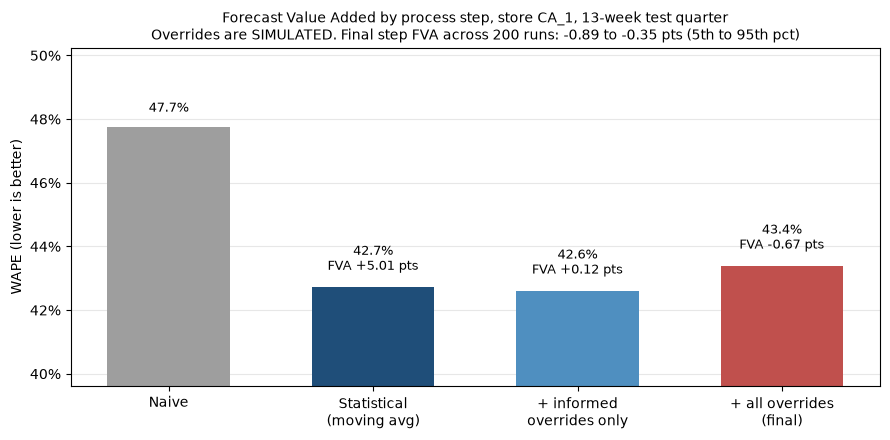

In [9]:
labels = ["Naive", "Statistical\n(moving avg)", "+ informed\noverrides only", "+ all overrides\n(final)"]
vals = stair["WAPE"].to_numpy()
colors = ["#9e9e9e", "#1f4e79", "#4f8fc0", "#c0504d"]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, vals, color=colors, width=0.6)
for b, v, fva in zip(bars, vals, stair["FVA vs previous step (pts)"]):
    txt = f"{v:.1%}" if np.isnan(fva) else f"{v:.1%}\nFVA {fva:+.2f} pts"
    ax.text(b.get_x() + b.get_width() / 2, v + 0.004, txt, ha="center", va="bottom", fontsize=9)
lo, hi = np.percentile(mc["FVA all overrides (pts)"], [5, 95])
ax.set_title(f"Forecast Value Added by process step, store {STORE_ID}, 13-week test quarter\n"
             f"Overrides are SIMULATED. Final step FVA across {N_SIMS} runs: {lo:+.2f} to {hi:+.2f} pts (5th to 95th pct)",
             fontsize=10)
ax.set_ylabel("WAPE (lower is better)")
ax.set_ylim(min(vals) - 0.03, max(vals) + 0.025)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fva_stairstep_{STORE_ID}.png", dpi=150, bbox_inches="tight")
plt.show()

Note: the y-axis does not start at 0, to make the small differences between steps visible. The labels give the exact values.

## Step 5. Where do overrides help, and where do they hurt?

FVA for a group of overrides is measured **only on the SKU-weeks that were overridden**:
$$\text{FVA}_{\text{group}} = \text{WAPE}(F_{\text{stat}}) - \text{WAPE}(F_{\text{final}}) \quad \text{on the overridden SKU-weeks in that group}$$

Groups:
- **Type:** informed (price) vs tinkering
- **Direction:** up (forecast raised) vs down (forecast lowered)
- **Size:** absolute adjustment under 10%, 10% to 25%, over 25%

These use the seed-42 run. The Monte Carlo check after the table repeats the direction split over all 200 runs.

In [10]:
ov = fc[fc["override_type"] != "none"].copy()
ov["direction"] = np.where(ov["override_pct"] > 0, "up", "down")
ov["size"] = pd.cut(ov["override_pct"].abs(), [-0.001, 0.10, 0.25, np.inf],
                    labels=["under 10%", "10% to 25%", "over 25%"])

def group_fva(g):
    a, s, f = g["units"].to_numpy(float), g["moving_avg"].to_numpy(float), g["final"].to_numpy(float)
    ws, wf = np.abs(a - s).sum() / a.sum(), np.abs(a - f).sum() / a.sum()
    return pd.Series({"SKU-weeks": len(g), "WAPE stat": ws, "WAPE final": wf,
                      "FVA (pts)": (ws - wf) * 100,
                      "Bias stat": (s - a).sum() / a.sum(), "Bias final": (f - a).sum() / a.sum()})

fmt = {"SKU-weeks": "{:,.0f}", "WAPE stat": "{:.1%}", "WAPE final": "{:.1%}", "FVA (pts)": "{:+.1f}",
       "Bias stat": "{:+.1%}", "Bias final": "{:+.1%}"}
by_type_dir = ov.groupby(["override_type", "direction"]).apply(group_fva, include_groups=False)
display(by_type_dir.style.format(fmt).set_caption("By type and direction"))
by_type_size = ov.groupby(["override_type", "size"], observed=True).apply(group_fva, include_groups=False)
display(by_type_size.style.format(fmt).set_caption("By type and size"))

In [11]:
# Monte Carlo check: tinkering FVA by direction across all runs
rows = []
for s in range(N_SIMS):
    f, t = simulate(np.random.default_rng(s))
    pct = np.where(STAT > 0, f / np.where(STAT > 0, STAT, 1) - 1, 0)
    for d, m in [("up", (t == "tinkering") & (pct > 0)), ("down", (t == "tinkering") & (pct < 0))]:
        rows.append({"direction": d, "FVA (pts)": (wape(STAT, m) - wape(f, m)) * 100})
dir_mc = pd.DataFrame(rows).groupby("direction")["FVA (pts)"].describe(percentiles=[0.05, 0.95])
dir_mc[["mean", "5%", "95%"]].style.format("{:+.1f}").set_caption(
    f"Tinkering FVA on overridden SKU-weeks, by direction, {N_SIMS} runs")

,mean,5%,95%
direction,,,
down,-1.1,-2.6,+0.3
up,-4.2,-5.9,-2.5


In [12]:
# FVA of all overrides by category (seed-42 run), measured on all SKU-weeks in the category
cat_rows = []
for cat, idx in fc.groupby("cat_id").groups.items():
    m = fc.index.isin(idx)
    cat_rows.append({"Category": cat, "WAPE stat": wape(STAT, m), "WAPE final": wape(final, m),
                     "FVA (pts)": (wape(STAT, m) - wape(final, m)) * 100,
                     "Bias stat": bias(STAT, m), "Bias final": bias(final, m)})
pd.DataFrame(cat_rows).set_index("Category").style.format(
    {"WAPE stat": "{:.1%}", "WAPE final": "{:.1%}", "FVA (pts)": "{:+.2f}",
     "Bias stat": "{:+.1%}", "Bias final": "{:+.1%}"})

,WAPE stat,WAPE final,FVA (pts),Bias stat,Bias final
Category,,,,,
FOODS,42.0%,42.8%,-0.83,-7.7%,-6.5%
HOBBIES,45.9%,46.1%,-0.18,-0.7%,-0.2%
HOUSEHOLD,43.3%,43.7%,-0.41,-1.4%,-0.6%


### Chart: FVA by override type and direction

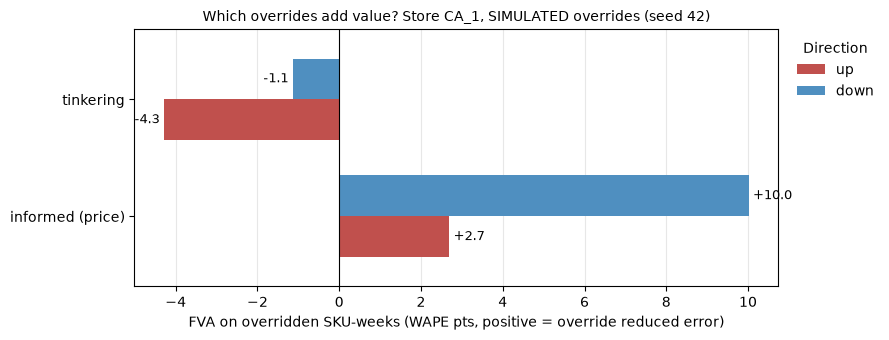

In [13]:
plot_df = by_type_dir["FVA (pts)"].unstack("direction")[["up", "down"]]
ax = plot_df.plot(kind="barh", figsize=(9, 3.5), color=["#c0504d", "#4f8fc0"], width=0.7)
ax.axvline(0, color="black", lw=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%+.1f", padding=3, fontsize=9)
ax.set_xlabel("FVA on overridden SKU-weeks (WAPE pts, positive = override reduced error)")
ax.set_ylabel("")
ax.set_title(f"Which overrides add value? Store {STORE_ID}, SIMULATED overrides (seed {SEED})", fontsize=10)
ax.legend(title="Direction", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fva_by_override_type_{STORE_ID}.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 6. Sensitivity analysis: do the conclusions survive different assumptions?

The override results depend on assumptions. Two tests:

1. **Tinkering:** vary the optimism bias $\mu$ (from $-10\%$ to $+10\%$) and judgment noise $\sigma$ (from 5% to 25%). Each cell is the average FVA of all overrides over 50 runs.
2. **Informed overrides:** vary the elasticity $\varepsilon$ the planner uses (from $-0.5$ to $-3$). This part has no randomness.

In [14]:
MUS = [-0.10, -0.05, 0.0, 0.05, 0.10]
SDS = [0.05, 0.10, 0.15, 0.25]
N_GRID = 50
grid = pd.DataFrame(index=[f"{s:.0%}" for s in SDS], columns=[f"{m:+.0%}" for m in MUS], dtype=float)
grid_tink = grid.copy()
for sd in SDS:
    for mu in MUS:
        tot, tk = [], []
        for s in range(N_GRID):
            f, t = simulate(np.random.default_rng(s), mu=mu, sd=sd)
            tot.append((w_stat - wape(f)) * 100)
            m = t == "tinkering"
            tk.append((wape(STAT, m) - wape(f, m)) * 100)
        grid.loc[f"{sd:.0%}", f"{mu:+.0%}"] = np.mean(tot)
        grid_tink.loc[f"{sd:.0%}", f"{mu:+.0%}"] = np.mean(tk)
grid.index.name = "noise sigma"
grid.columns.name = "optimism bias mu"
grid_tink.index.name, grid_tink.columns.name = grid.index.name, grid.columns.name
print("FVA of tinkering, on tinkered SKU-weeks only (pts)")
display(grid_tink.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-6, vmax=6))
print("FVA of ALL overrides (informed + tinkering), on all SKU-weeks (pts)")
display(grid.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1.5, vmax=1.5))

FVA of tinkering, on tinkered SKU-weeks only (pts)


optimism bias mu,-10%,-5%,+0%,+5%,+10%
noise sigma,,,,,
5%,-0.63,-0.18,-0.31,-1.00,-2.25
10%,-1.42,-1.02,-1.15,-1.84,-3.05
15%,-2.69,-2.34,-2.49,-3.15,-4.31
25%,-6.41,-6.14,-6.30,-6.89,-7.92


FVA of ALL overrides (informed + tinkering), on all SKU-weeks (pts)


optimism bias mu,-10%,-5%,+0%,+5%,+10%
noise sigma,,,,,
5%,-0.03,+0.07,+0.05,-0.12,-0.41
10%,-0.22,-0.12,-0.15,-0.32,-0.60
15%,-0.52,-0.44,-0.47,-0.63,-0.90
25%,-1.40,-1.33,-1.37,-1.51,-1.75


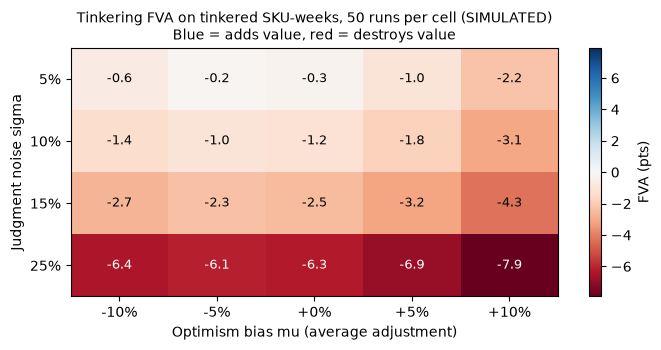

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
vmax = np.nanmax(np.abs(grid_tink.to_numpy()))
im = ax.imshow(grid_tink.to_numpy(float), cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(MUS)), grid_tink.columns)
ax.set_yticks(range(len(SDS)), grid_tink.index)
ax.set_xlabel("Optimism bias mu (average adjustment)")
ax.set_ylabel("Judgment noise sigma")
for i in range(len(SDS)):
    for j in range(len(MUS)):
        v = grid_tink.iloc[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 * vmax else "black")
fig.colorbar(im, ax=ax, label="FVA (pts)")
ax.set_title(f"Tinkering FVA on tinkered SKU-weeks, {N_GRID} runs per cell (SIMULATED)\n"
             "Blue = adds value, red = destroys value", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fva_sensitivity_{STORE_ID}.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
rng0 = np.random.default_rng(0)  # tinkering does not affect price-change weeks, so any seed works
el_rows = []
for e in [-0.5, -1.0, -1.5, -2.0, -3.0]:
    f, _ = simulate(rng0, elasticity=e)
    el_rows.append({"Elasticity used": e, "WAPE stat (price weeks)": wape(STAT, PRICE_ACT),
                    "WAPE final (price weeks)": wape(f, PRICE_ACT),
                    "FVA (pts, price weeks)": (wape(STAT, PRICE_ACT) - wape(f, PRICE_ACT)) * 100,
                    "Bias final (price weeks)": bias(f, PRICE_ACT)})
pd.DataFrame(el_rows).set_index("Elasticity used").style.format(
    {"WAPE stat (price weeks)": "{:.1%}", "WAPE final (price weeks)": "{:.1%}",
     "FVA (pts, price weeks)": "{:+.1f}", "Bias final (price weeks)": "{:+.1%}"})

,WAPE stat (price weeks),WAPE final (price weeks),"FVA (pts, price weeks)",Bias final (price weeks)
Elasticity used,,,,
-0.500000,63.5%,60.2%,+3.4,-9.6%
-1.000000,63.5%,58.2%,+5.3,-13.7%
-1.500000,63.5%,57.0%,+6.5,-17.2%
-2.000000,63.5%,56.3%,+7.2,-20.2%
-3.000000,63.5%,56.2%,+7.3,-24.6%


## Step 7. Test override policies

An **override policy** is a rule for which planner changes get accepted into the final forecast. Each policy below is applied to every one of the 200 simulated runs.

| Policy | Rule |
|---|---|
| P0. No overrides | Use the statistical forecast as is |
| P1. Accept all | Every override goes into the final forecast (no governance) |
| P2. Reason code required | Accept only overrides with a documented reason (here: a known price change). Reject the rest |
| P3. Size threshold | Accept only overrides of 10% or more, with or without a reason |
| P4. Down only | Accept only overrides that lower the forecast |

In [17]:
def apply_policy(f, t, policy):
    pct = np.where(STAT > 0, f / np.where(STAT > 0, STAT, 1) - 1, 0)
    keep = {
        "P0. No overrides": np.zeros(len(f), bool),
        "P1. Accept all": t != "none",
        "P2. Reason code required": t == "informed (price)",
        "P3. Size threshold (10%+)": (t != "none") & (np.abs(pct) >= 0.10),
        "P4. Down only": (t != "none") & (pct < 0),
    }[policy]
    return np.where(keep, f, STAT), keep

POLICIES = ["P0. No overrides", "P1. Accept all", "P2. Reason code required",
            "P3. Size threshold (10%+)", "P4. Down only"]
rows = []
for s in range(N_SIMS):
    f, t = simulate(np.random.default_rng(s))
    for p in POLICIES:
        g, keep = apply_policy(f, t, p)
        rows.append({"Policy": p, "WAPE": wape(g), "Bias": bias(g),
                     "FVA vs stat (pts)": (w_stat - wape(g)) * 100, "Overrides kept": keep.mean()})
pol = pd.DataFrame(rows)
pol_summary = pol.groupby("Policy").agg(
    WAPE=("WAPE", "mean"), Bias=("Bias", "mean"),
    FVA_mean=("FVA vs stat (pts)", "mean"),
    FVA_p5=("FVA vs stat (pts)", lambda x: np.percentile(x, 5)),
    FVA_p95=("FVA vs stat (pts)", lambda x: np.percentile(x, 95)),
    share_kept=("Overrides kept", "mean"),
).loc[POLICIES]
pol_summary.columns = ["WAPE", "Bias", "FVA vs stat (pts)", "FVA 5th pct", "FVA 95th pct",
                       "SKU-weeks overridden"]
pol_summary.style.format({"WAPE": "{:.2%}", "Bias": "{:+.2%}", "FVA vs stat (pts)": "{:+.2f}",
                          "FVA 5th pct": "{:+.2f}", "FVA 95th pct": "{:+.2f}",
                          "SKU-weeks overridden": "{:.1%}"})

,WAPE,Bias,FVA vs stat (pts),FVA 5th pct,FVA 95th pct,SKU-weeks overridden
Policy,,,,,,
P0. No overrides,42.73%,-5.55%,+0.00,+0.00,+0.00,0.0%
P1. Accept all,43.33%,-4.59%,-0.60,-0.89,-0.35,16.6%
P2. Reason code required,42.61%,-5.77%,+0.12,+0.12,+0.12,1.5%
P3. Size threshold (10%+),43.29%,-4.66%,-0.56,-0.83,-0.30,9.2%
P4. Down only,42.73%,-6.76%,-0.00,-0.16,+0.12,6.4%


### Recommended override policy

Based on the policy test above (all numbers are averages over 200 simulated runs, so they show how the policies compare under the stated assumptions, not a measured result from real planners):

1. **Require a reason code for every override (P2).** Only overrides tied to information the system does not have (here, a known price change) are accepted. Result: WAPE 42.61% vs 42.73% with no overrides (+0.12 pts) while touching only 1.5% of SKU-weeks. Accepting every override (P1) gave 43.33% (-0.60 pts) while touching 16.6% of SKU-weeks. Planners do about a tenth of the work and get a better forecast.
2. **Do not use size or direction rules as a shortcut.** A 10%+ size threshold (P3) still destroyed value (-0.56 pts), and accepting only downward changes (P4) added nothing (0.00 pts) and pushed bias further negative (-6.76%). Large tinkering adjustments were the most harmful group (-16.4 pts on those SKU-weeks in the seed-42 run).
3. **Report FVA every month by reason code (and by planner, with real data).** Keep a reason code only while its FVA stays positive. This is how the policy stays honest once real override logs exist.
4. **Fix bias in the statistical step, not with overrides.** Random upward tweaks reduced bias (-5.55% to -4.59%) but increased error. That is not value added. The real under-forecast (FOODS growth, notebook 02) should be handled in the model, for example by a shorter window or a trend term, and checked with FVA.
5. **Create a separate process for zero-forecast items that come back (relaunch or back-in-stock).** 39 SKUs had a moving average of 0 when their price changed and then sold 2,642 units in those weeks. No % override can fix a forecast of 0, so planners need to enter a unit forecast for them.
6. **Price-cut adjustments need a bigger lift than -1.5 elasticity implies.** Even after the informed override, price-cut weeks were still under-forecast by 36%. The elasticity sensitivity shows stronger elasticities kept improving WAPE. A real team should estimate lift from past price cuts rather than use one rule of thumb.

## Save the simulated override log

In [18]:
log_cols = ["item_id", "dept_id", "cat_id", "tier", "wm_yr_wk", "week_start", "h", "units",
            "sell_price", "price_chg", "naive", "moving_avg", "override_type", "override_pct", "final"]
out = PROCESSED_DIR / f"overrides_sim_{STORE_ID}.parquet"
fc[log_cols].to_parquet(out, index=False)
print(f"Saved {len(fc):,} rows to {out.relative_to(PROJECT_DIR)} (seed {SEED}, SIMULATED overrides)")

Saved 35,321 rows to data/processed/overrides_sim_CA_1.parquet (seed 42, SIMULATED overrides)


## Reading the results (fill in after running)
Write 3 to 5 bullets per prompt in your own words, based on the tables above.
- Real result: how much value does the statistical forecast add over naive, overall and by category?
    - The moving average adds 5.0 points over naive: 42.7% WAPE vs 47.7%.
    - It adds value in every category: FOODS +4.4 points, HOUSEHOLD +5.3, HOBBIES +8.0. (Notebook 02 says 8.1 for HOBBIES. That’s just rounding: 54.0 minus 45.9 looks like 8.1, but the unrounded gap is 8.0.)
    - Not every method adds value. LightGBM adds +1.8 points, but Holt-Winters is -0.9 and seasonal naive is -13.8, so both are worse than doing nothing.
    - Why: averaging 4 weeks cancels out random highs and lows. Naive bets everything on a single week.
    - What it means: the statistical step is worth keeping. Being more complex doesn’t guarantee positive FVA, so every method has to earn its place against naive.

- Simulated: do informed (price) overrides add value? On how many SKU-weeks, and how much does that move total WAPE?
    - Yes. They touch 543 SKU-weeks (1.5% of all SKU-weeks, 71 SKUs). On those weeks, WAPE drops from 63.5% to 57.0%, a gain of 6.5 points.
    - Total WAPE moves only from 42.73% to 42.61%, a gain of 0.12 points, because so few weeks are touched.
    - Price increases gain the most (+10.0 points), and bias on those weeks goes from +31.9% to +0.1%. Price cuts gain +2.7 points, but those weeks are still under-forecast by 36%.
    - Every elasticity tested, from -0.5 to -3, helped (+3.4 to +7.3 points), so the result doesn’t hinge on the -1.5 assumption.
    - Why: the moving average only looks at past sales and can’t react to a price change. The planner knows about the price change ahead of time, so the planner has information the model lacks.
    - What it means: overrides add value when they bring in new information. Price cuts need a bigger lift than a simple rule of thumb gives, so a real team should estimate the lift from past price cuts.
    - Separate finding: 295 price-change weeks had a forecast of 0 (39 SKUs, 2,642 units sold). A % override can’t fix a zero, so these items need their own process.

- Simulated: does tinkering add or destroy value? Does the answer change across the sensitivity grid? Is there any cell where tinkering helps, and why?
    - It destroys value. On the SKU-weeks it touches, it costs 3.0 points on average over 200 runs. Upward tweaks cost 4.3 points and downward tweaks 1.1 (seed 42 run). Tweaks bigger than 25% cost 16.4 points.
    - The answer holds across the whole grid. Tinkering is negative in all 20 cells, from -0.2 to -7.9 points.
    - No cell shows tinkering helping. The combined grid has two small positives (+0.05 and +0.07 at 5% noise), but those come from the informed overrides’ +0.12 outweighing a small tinkering loss.
    - Noise matters more than bias. Going from 5% to 25% noise costs about 6 points. Changing the bias from -10% to +10% moves the result by only about 1 to 2 points.
    - Why: an adjustment with no new information just moves the forecast away from the model’s best estimate in a random direction, which adds error on average.
    - Honest caveat: this result is partly built in, because tinkering has no information by design. The real question for a company is whether its planners’ overrides carry information, and FVA is how you measure that.

- Which override policy gives the lowest WAPE and bias, and how much planner effort (share of SKU-weeks overridden) does it need?
    - Lowest WAPE: P2, reason code required. It scores 42.61%, the only policy that beats no overrides (42.73%), and it touches only 1.5% of SKU-weeks.
    - Accepting every override (P1) scores 43.33% and touches 16.6% of SKU-weeks. That is about 11 times the planner effort for a worse forecast.
    - Bias closest to 0: P1 (-4.59%). P2 is slightly worse at -5.77%. So no single policy wins on both.
    - Why P1’s bias looks better: the random tweaks lean upward, and that happens to offset the real under-forecast. Error goes up anyway, so the lower bias is luck, not value added.
    - The other policies don’t help either. The 10%+ size threshold (P3) still loses 0.56 points, and accepting only downward changes (P4) adds nothing while pushing bias down to -6.76%.
    - What it means: require a reason code for every override, and fix bias in the statistical model (for example, FOODS growth), not through overrides.

- What would you need from a real company to confirm these findings?
    - A real override log: the system forecast at the moment of the override, the final forecast, who made it, when, and the reason code.
    - Prices and promotions as they were planned at forecast time, not the actual prices. My simulation assumes planners knew the actual test prices.
    - Inventory or stockout data, so you can tell weeks where demand was low from weeks where the shelf was empty, since sales are not demand.
    - Several quarters and stores, so the result isn’t specific to one store and one quarter.
    - A method chosen on an earlier backtest quarter. The moving average was picked on this same test quarter.
    - With that data, you run the same stairstep and policy test on real overrides, with no simulation.

## Limitations
- **Overrides are simulated.** The size of the override FVA depends on the assumed touch rates, optimism bias, noise, and elasticity. The method (stairstep FVA, group FVA, policy test) is what carries over to real data
- The informed override assumes the planner knows test-quarter prices in advance (same assumption as LightGBM in notebook 02) and uses one elasticity for every item
- The statistical forecast (moving average) was chosen on this same test quarter. A stricter test would choose it on an earlier backtest quarter
- One store, one quarter (2016-02-20 to 2016-05-14), 2,717 SKUs with 2+ years of history
- M5 records sales, not demand. Stockouts hide unmet demand